![](https://www.gannett-cdn.com/-mm-/0b146ca359d26300e1d6a8b6a2d86ce731de39c2/c=10-0-630-466/local/-/media/2016/12/10/INGroup/Indianapolis/636169619660823711-121116.jpg?quality=50&width=640)

The spread of misinformation on social media platforms is an ever-growing problem. Organizations, politicians, individuals looking for personal gain and even certain news media outlets engage in propagating fake news to sway people's decisions as well as distorting events to fit a bias or prejudice. 

The degree of authenticity of the news posted online cannot be definitively measured, since the manual classification of news is tedious and time-consuming and is also subject to bias. 

To tackle the growing problem, detection, classification and mitigation tools are a need of the hour.

# Methodology
The categories, bs (i.e. bullshit), junksci(i.e. junk science), hate, fake, conspiracy, bias, satire and state declare the
category under which untrustworthy or false news fall under. 

The first step, which is text preprocessing was performed using the following:
* Taking care of null/missing values 
* Transforming categorical data with the help of label encoders 
* Uppercase to lowercase 
* Number removal 
* Tokenization 
* Stop Word Removal, Stemming and Lemmatization (with POS tagging) using the Natural Language Toolkit Library 

For feature engineering, the TF-IDF technique is used. 
This processed and embedded text is provided as an input to Machine learning models, where the data is made to fit the model, to get a prediction as an output. 

In [1]:
import multiprocessing

multiprocessing.cpu_count()

12

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 5GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Imports

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import cufflinks as cf
import plotly
import plotly.express as px
import seaborn as sns

from IPython.core.display import HTML
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from datetime import datetime
from sklearn.feature_extraction.text import CountVectorizer
from pandas import DataFrame
from collections import OrderedDict 
from colorama import Fore, Back, Style
y_ = Fore.YELLOW
r_ = Fore.RED
g_ = Fore.GREEN
b_ = Fore.BLUE
m_ = Fore.MAGENTA
sr_ = Style.RESET_ALL

# Reading the csv file

In [6]:
df = pd.read_csv(r'/home/sakdag/weakly-supervised-fake-news-classification/data/temp/news_articles.csv', encoding="latin", index_col=0)
df = df.dropna()
df.count()

published                  2045
title                      2045
text                       2045
language                   2045
site_url                   2045
main_img_url               2045
type                       2045
label                      2045
title_without_stopwords    2045
text_without_stopwords     2045
hasImage                   2045
dtype: int64

In [7]:
df.head(5)

,published,title,text,language,site_url,main_img_url,type,label,title_without_stopwords,text_without_stopwords,hasImage
author,,,,,,,,,,,
Barracuda Brigade,2016-10-26T21:41:00.000+03:00,muslims busted they stole millions in govt ben...,print they should pay all the back all the mon...,english,100percentfedup.com,http://bb4sp.com/wp-content/uploads/2016/10/Fu...,bias,Real,muslims busted stole millions govt benefits,print pay back money plus interest entire fami...,1.0
reasoning with facts,2016-10-29T08:47:11.259+03:00,re why did attorney general loretta lynch plea...,why did attorney general loretta lynch plead t...,english,100percentfedup.com,http://bb4sp.com/wp-content/uploads/2016/10/Fu...,bias,Real,attorney general loretta lynch plead fifth,attorney general loretta lynch plead fifth bar...,1.0
Barracuda Brigade,2016-10-31T01:41:49.479+02:00,breaking weiner cooperating with fbi on hillar...,red state \nfox news sunday reported this mor...,english,100percentfedup.com,http://bb4sp.com/wp-content/uploads/2016/10/Fu...,bias,Real,breaking weiner cooperating fbi hillary email ...,red state fox news sunday reported morning ant...,1.0
Fed Up,2016-11-01T05:22:00.000+02:00,pin drop speech by father of daughter kidnappe...,email kayla mueller was a prisoner and torture...,english,100percentfedup.com,http://100percentfedup.com/wp-content/uploads/...,bias,Real,pin drop speech father daughter kidnapped kill...,email kayla mueller prisoner tortured isis cha...,1.0
Fed Up,2016-11-01T21:56:00.000+02:00,fantastic trumps point plan to reform healthc...,email healthcare reform to make america great ...,english,100percentfedup.com,http://100percentfedup.com/wp-content/uploads/...,bias,Real,fantastic trumps point plan reform healthcare ...,email healthcare reform make america great sin...,1.0


In [8]:
df['type'].unique()

array(['bias', 'conspiracy', 'fake', 'bs', 'satire', 'hate', 'junksci',
       'state'], dtype=object)

In [9]:
cf.go_offline()
cf.set_config_file(offline=False, world_readable=True)

# Distrubution of types of articles

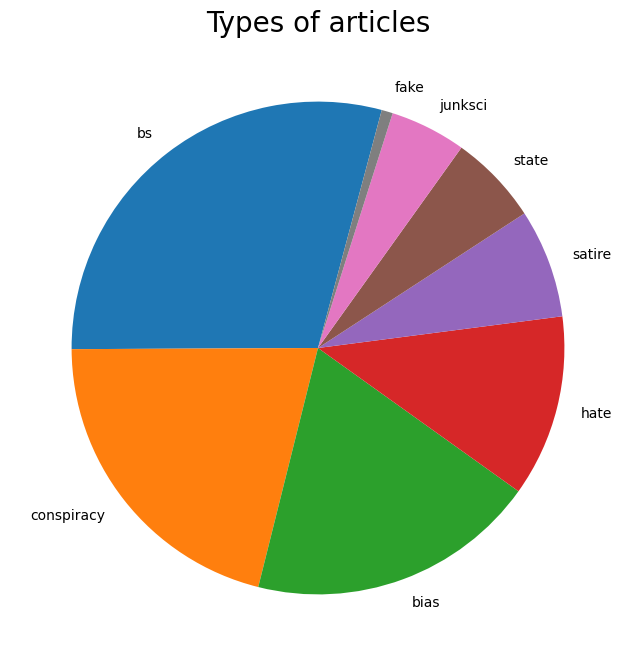

In [10]:
df['type'].value_counts().plot.pie(figsize = (8,8), startangle = 75)
plt.title('Types of articles', fontsize = 20)
plt.axis('off')
plt.show()

# Unigrams and bigrams 

In [11]:
def get_top_n_words(corpus, n=None):
    vec = CountVectorizer().fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0) 
    words_freq = [(word, sum_words[0, idx]) for word, idx in     vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

def get_top_n_bigram(corpus, n=None):
    vec = CountVectorizer(ngram_range=(2, 2)).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0) 
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]


def get_top_n_trigram(corpus, n=None):
    vec = CountVectorizer(ngram_range=(3, 3)).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0) 
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

In [12]:
common_words = get_top_n_words(df['text_without_stopwords'], 20)
df2 = DataFrame (common_words,columns=['word','count'])
df2.groupby('word').sum()['count'].sort_values(ascending=False).iplot(
    kind='bar', yTitle='Count', linecolor='black', title='Top 20 unigrams used in articles',color='blue')

In [13]:
common_words = get_top_n_bigram(df['text_without_stopwords'], 20)
df3 = pd.DataFrame(common_words, columns = ['words' ,'count'])
df3.groupby('words').sum()['count'].sort_values(ascending=False).iplot(
    kind='bar', yTitle='Count', linecolor='black', title='Top 20 bigrams used in articles', color='blue')

# WordCloud of articles

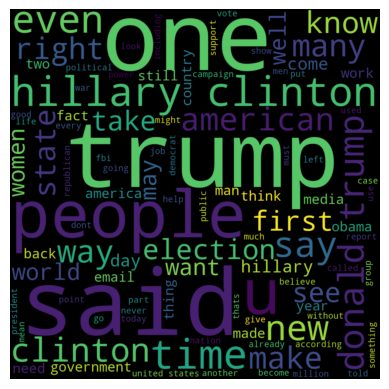

In [14]:
wc = WordCloud(background_color="black", max_words=100,
               max_font_size=256,
               random_state=42, width=1000, height=1000)
wc.generate(' '.join(df['text_without_stopwords']))
plt.imshow(wc, interpolation="bilinear")
plt.axis('off')
plt.show()

# Articles including images vs Label

In [15]:
fig = px.bar(df, x='hasImage', y='label',title='Articles including images vs Label')
fig.show()

In [16]:
def convert(path):
    return '<img src="'+ path + '" width="80">'

In [17]:
df_sources = df[['site_url','label','main_img_url']]
df_r = df_sources.loc[df['label']== 'Real'].iloc[6:10,:]
df_f = df_sources.loc[df['label']== 'Fake'].head(6)

In [18]:
HTML(df_r.to_html(escape=False,formatters=dict(main_img_url=convert)))

,site_url,label,main_img_url
author,,,
Fed Up,100percentfedup.com,Real,
Fed Up,100percentfedup.com,Real,
Fed Up,100percentfedup.com,Real,
Fed Up,100percentfedup.com,Real,


In [19]:
HTML(df_f.to_html(escape=False,formatters=dict(main_img_url=convert)))

,site_url,label,main_img_url
author,,,
No Author,21stcenturywire.com,Fake,
No Author,21stcenturywire.com,Fake,
Shawn Helton,21stcenturywire.com,Fake,
Mike Rivero,21stcenturywire.com,Fake,
No Author,21stcenturywire.com,Fake,
Shawn Helton,21stcenturywire.com,Fake,


In [20]:
df['site_url'].unique()

array(['100percentfedup.com', '21stcenturywire.com', 'abcnews.com.co',
       'abeldanger.net', 'abovetopsecret.com', 'activistpost.com',
       'addictinginfo.org', 'adobochronicles.com', 'ahtribune.com',
       'allnewspipeline.com', 'americannews.com',
       'americasfreedomfighters.com', 'amren.com', 'amtvmedia.com',
       'awdnews.com', 'barenakedislam.com', 'clickhole.com',
       'coasttocoastam.com', 'corbettreport.com', 'countercurrents.org',
       'counterpunch.org', 'dailywire.com', 'darkmoon.me',
       'davidduke.com', 'davidstockmanscontracorner.com',
       'davidwolfe.com', 'dcclothesline.com', 'defenddemocracy.press',
       'dennismichaellynch.com', 'departed.co', 'der-postillon.com',
       'fromthetrenchesworldreport.com', 'frontpagemag.com',
       'galacticconnection.com', 'globalresearch.ca', 'infowars.com',
       'intrepidreport.com', 'legorafi.fr', 'madworldnews.com',
       'naturalnews.com', 'newstarget.com', 'politicususa.com',
       'presstv.com', 'pre

In [21]:
type_label = {'Real': 0, 'Fake': 1}
df_sources.label = [type_label[item] for item in df_sources.label] 

In [22]:
val_real=[]
val_fake=[]

for i,row in df_sources.iterrows():
    val = row['site_url']
    if row['label'] == 0:
        val_real.append(val)
    elif row['label']== 1:
        val_fake.append(val)

> # Websites publishing real news

In [23]:
uniqueValues_real = list(OrderedDict.fromkeys(val_real)) 

print(f"{y_}Websites publishing real news:{g_}{uniqueValues_real}\n") 

Websites publishing real news:['100percentfedup.com', 'addictinginfo.org', 'dailywire.com', 'davidduke.com', 'fromthetrenchesworldreport.com', 'frontpagemag.com', 'newstarget.com', 'politicususa.com', 'presstv.com', 'presstv.ir', 'prisonplanet.com', 'proudemocrat.com', 'redstatewatcher.com', 'returnofkings.com', 'washingtonsblog.com', 'westernjournalism.com', 'whydontyoutrythis.com', 'wnd.com']



# Websites publishing fake news

In [24]:
uniqueValues_fake = list(OrderedDict.fromkeys(val_fake)) 
print(f"{y_}Websites publishing fake news:{r_}{uniqueValues_fake}\n")

Websites publishing fake news:['21stcenturywire.com', 'abcnews.com.co', 'abeldanger.net', 'abovetopsecret.com', 'activistpost.com', 'adobochronicles.com', 'ahtribune.com', 'allnewspipeline.com', 'americannews.com', 'americasfreedomfighters.com', 'amren.com', 'amtvmedia.com', 'awdnews.com', 'barenakedislam.com', 'clickhole.com', 'coasttocoastam.com', 'corbettreport.com', 'countercurrents.org', 'counterpunch.org', 'darkmoon.me', 'davidduke.com', 'davidstockmanscontracorner.com', 'davidwolfe.com', 'dcclothesline.com', 'defenddemocracy.press', 'dennismichaellynch.com', 'departed.co', 'der-postillon.com', 'fromthetrenchesworldreport.com', 'frontpagemag.com', 'galacticconnection.com', 'globalresearch.ca', 'infowars.com', 'intrepidreport.com', 'legorafi.fr', 'madworldnews.com', 'naturalnews.com', 'newstarget.com', 'presstv.ir', 'prisonplanet.com', 'projectveritas.com', 'returnofkings.com', 'shiftfrequency.com', 'thedailysheeple.com', 'theeconomiccollapseblog.com', 'thefreethoughtproject.com',

# Websites publishing both real and fake news

In [25]:
real_set = set(uniqueValues_real) 
fake_set = set(uniqueValues_fake) 

print(f"{y_}Websites publishing both real and fake news:{m_}{real_set & fake_set}\n")

Websites publishing both real and fake news:{'prisonplanet.com', 'washingtonsblog.com', 'davidduke.com', 'newstarget.com', 'fromthetrenchesworldreport.com', 'returnofkings.com', 'presstv.ir', 'frontpagemag.com', 'westernjournalism.com'}



In [26]:
type1 = {'bias': 0, 'conspiracy': 1,'fake': 2,'bs': 3,'satire': 4, 'hate': 5,'junksci': 6, 'state': 7}
df.type = [type1[item] for item in df.type] 

In [27]:
def plot_bar(df, feat_x, feat_y, normalize=True):
    """ Plot with vertical bars of the requested dataframe and features"""
    
    ct = pd.crosstab(df[feat_x], df[feat_y])
    if normalize == True:
        ct = ct.div(ct.sum(axis=1), axis=0)
    return ct.plot(kind='bar', stacked=True)

# Label vs Type

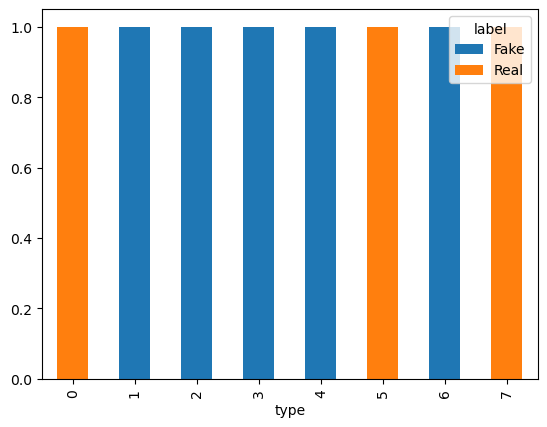

In [28]:
plot_bar(df,'type' , 'label')
plt.show()

In [29]:
fig = px.sunburst(df, path=['label', 'type'])
fig.show()

# Websites and types of news published

In [30]:
df_type = df[['site_url','type']]

val_bias=[]
val_conspiracy=[]
val_fake1=[]
val_bs=[]
val_satire=[]
val_hate=[]
val_junksci=[]
val_state=[]
{'bias': 0, 'conspiracy': 1,'fake': 2,'bs': 3,'satire': 4, 'hate': 5,'junksci': 6, 'state': 7}
for i,row in df_type.iterrows():
    val = row['site_url']
    if row['type'] == 0:
        val_bias.append(val)
    elif row['type']== 1:
        val_conspiracy.append(val)
    elif row['type']== 2:
        val_fake1.append(val)
    elif row['type']== 3:
        val_bs.append(val)
    elif row['type']== 4:
        val_satire.append(val)
    elif row['type']== 5:
        val_hate.append(val)
    elif row['type']== 6:
        val_junksci.append(val)
    elif row['type']== 7:
        val_state.append(val)

In [31]:
uv_bias = list(OrderedDict.fromkeys(val_bias)) 
uv_conspiracy = list(OrderedDict.fromkeys(val_conspiracy)) 
uv_fake = list(OrderedDict.fromkeys(val_fake1)) 
uv_bs = list(OrderedDict.fromkeys(val_bs)) 
uv_satire = list(OrderedDict.fromkeys(val_satire)) 
uv_hate = list(OrderedDict.fromkeys(val_hate)) 
uv_junksci = list(OrderedDict.fromkeys(val_junksci)) 
uv_state = list(OrderedDict.fromkeys(val_state)) 

print(f"{b_}{type1}\n")
i=0
for lst in (uv_bias,uv_conspiracy,uv_fake,uv_bs,uv_satire, uv_hate,uv_junksci,uv_state): 
    print(f"{y_}Source URLs for type:{b_}{i}{r_}{lst}\n") 
    i+=1

{'bias': 0, 'conspiracy': 1, 'fake': 2, 'bs': 3, 'satire': 4, 'hate': 5, 'junksci': 6, 'state': 7}

Source URLs for type:0['100percentfedup.com', 'addictinginfo.org', 'dailywire.com', 'newstarget.com', 'politicususa.com', 'prisonplanet.com', 'proudemocrat.com', 'washingtonsblog.com', 'westernjournalism.com', 'whydontyoutrythis.com', 'wnd.com']

Source URLs for type:1['21stcenturywire.com', 'activistpost.com', 'awdnews.com', 'galacticconnection.com', 'globalresearch.ca', 'infowars.com', 'naturalnews.com', 'newstarget.com', 'presstv.ir', 'prisonplanet.com']

Source URLs for type:2['abcnews.com.co', 'adobochronicles.com']

Source URLs for type:3['abeldanger.net', 'abovetopsecret.com', 'ahtribune.com', 'allnewspipeline.com', 'americannews.com', 'americasfreedomfighters.com', 'amren.com', 'amtvmedia.com', 'barenakedislam.com', 'coasttocoastam.com', 'corbettreport.com', 'countercurrents.org', 'counterpunch.org', 'darkmoon.me', 'davidduke.com', 'davidstockmanscontracorner.com', 'davidwolfe.co

# Shuffling values

In [32]:
df1 = df.sample(frac=1)
df1.head()

,published,title,text,language,site_url,main_img_url,type,label,title_without_stopwords,text_without_stopwords,hasImage
author,,,,,,,,,,,
Don Anthony Dillon,2016-10-26T22:46:16.996+03:00,no title,obama lies all of the time he doesnt bother to...,english,westernjournalism.com,http://static.westernjournalism.com/wp-content...,0,Real,title,wow ever notice liar caught heshe cand cough l...,1.0
tokyowashi (noreply@blogger.com),2016-11-02T01:17:20.300+02:00,an explanation for why the fbi reopened hillar...,google david howarduh oh google meuh oh goog...,english,abeldanger.net,No Image URL,3,Fake,explanation fbi reopened hillarys emails,google david howarduh oh google meuh oh google...,0.0
Jo Coffelt,2016-10-26T22:46:37.509+03:00,no title,the wrh server is back to normal except for th...,english,westernjournalism.com,http://static.westernjournalism.com/wp-content...,0,Real,title,wmd announcement reminder site continues attac...,1.0
No Author,2016-11-20T07:00:00.000+02:00,presstvbrits enraged by royal familys costs,on the news line afp \nthese are some of the h...,english,presstv.com,http://media.presstv.com/photo/20161124/76b750...,7,Real,car bomb kills people south iraqi capital,news bulletin afp farewell old captain hundred...,1.0
Hefficide,2016-10-27T09:52:00.000+03:00,looking beyond november th a song of oligarch...,link greetings ats community i wanted to pass ...,english,abovetopsecret.com,http://files.abovetopsecret.com/images/ats6.jpg,3,Fake,looking beyond november th song oligarchy doom,link greetings ats community wanted pass somet...,1.0


# Training and Testing

In [33]:
y = df1.type

x = df1.loc[:,['site_url','text_without_stopwords']]
x['source'] = x["site_url"].astype(str) +" "+ x["text_without_stopwords"] 
x = x.drop(['site_url','text_without_stopwords'],axis=1)
x = x.source

In [49]:
for element in x:
    print(element)
    break

westernjournalism.com wow ever notice liar caught heshe cand cough lies cover lies speed know advance lying type cover lie needed true experts lies cya caught ovomit hitlery experts liars club cya gathering unbelievable ever tell american people sooner later comes back bite old butt


Right after preprocessing, the output is a corpus of raw texts that are stripped of stopwords, stemmed and lemmatized. 

In order to get a sparse matrix of TF/IDF values, the following steps are taken:
* Tokenization of texts
* Counting of the tokens and
* Transforming the raw tokens into TF/IDF values

The above steps are done with the help of the TfidfVectorizer, which transforms text to feature vectors that can be used
as input to estimators/classifiers.

In [34]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30)

tfidf_vect = TfidfVectorizer(stop_words = 'english')
tfidf_train = tfidf_vect.fit_transform(x_train)
tfidf_test = tfidf_vect.transform(x_test)
tfidf_df = pd.DataFrame(tfidf_train.A, columns=tfidf_vect.get_feature_names())

/home/sakdag/miniconda3/envs/fake-news-classification/lib/python3.10/site-packages/sklearn/utils/deprecation.py:87: FutureWarning:

Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.



In [35]:
tfidf_vect

TfidfVectorizer(stop_words='english')

In [36]:
tfidf_train.shape

(1431, 39396)

AdaBoost works in iterations with a base classifier to ensure accurate predictions of unusual observations.

It works in iterations and within each iteration, incorrect observations are given a higher probability for classification for the next iteration. 

The AdaBoost implemented here has a Decision Tree Classifier as the base classifier with a max depth of the tree being 10.

In [37]:
Adab = AdaBoostClassifier(DecisionTreeClassifier(max_depth=10),n_estimators=5,random_state=1)
Adab.fit(tfidf_train, y_train)
y_pred3 = Adab.predict(tfidf_test)
ABscore = metrics.accuracy_score(y_test,y_pred3)
print("accuracy: %0.3f" %ABscore)

accuracy: 0.963


In [38]:
Rando = RandomForestClassifier(n_estimators=100,random_state=0)
Rando.fit(tfidf_train,y_train)
y_pred1 = Rando.predict(tfidf_test)
RFscore = metrics.accuracy_score(y_test,y_pred1)
print("accuracy:  %0.3f" %RFscore)

accuracy:  0.855


In [ ]:
# sakdag my trials:

In [40]:
import sys

if "Desktop" in os.getcwd():
    base_path = "/Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification"
else:
    base_path = "/home/sakdag/weakly-supervised-fake-news-classification"

print(base_path)
sys.path.append(base_path)
    
from src.utils.path_utils import get_project_root
from src.preprocessing.consts import Datasets
from src.preprocessing.read_raw_data import read_raw_data

covid_df: pd.DataFrame = read_raw_data(Datasets.NELA_COVID_2021_DATASET_SAMPLED)

/home/sakdag/weakly-supervised-fake-news-classification
Reading dataset from path: /home/sakdag/weakly-supervised-fake-news-classification/data/raw/nela/nela-covid-2021-sampled.csv
Dataframe size: 19930


In [41]:
covid_df

,id,title,content,label
0,thedcclothesline--2021-10-20--Over 100 workers...,Over 100 workers sue top US nuclear weapons la...,( Natural News ) Over a hundred workers at the...,1
1,eveningstandard--2021-02-10--Boris Johnson to ...,Boris Johnson to give more details about schoo...,oris Johnson has said he will reveal more deta...,0
2,davidicke--2021-01-14--Blood disease scientist...,Blood disease scientist: A Medical Certainty P...,"Dr. Jerry L. Spivak , an expert on blood disor...",1
3,upi--2021-02-03--ADP-Moody's: U.S. economy add...,"ADP-Moody's: U.S. economy added 174,000 jobs i...",Feb. 3 ( UPI ) -- The U.S. economy added more ...,0
4,thenewyorktimes--2021-03-20--Virus Partially S...,Virus Partially Shuts Trump's Florida Club,Former President Donald J. Trump s private clu...,0
...,...,...,...,...
19925,thegatewaypundit--2021-07-29--It Begins: St. L...,It Begins: St. Louis Carpenters Union Forces A...,Democrats and global elites are now forcing ci...,1
19926,thenewyorktimes--2021-06-17--Canadian Couple W...,Canadian Couple Who Flew to Indigenous Town fo...,A Canadian couple who drew widespread criticis...,0
19927,needtoknow--2021-08-23--Romanians and Bulgaria...,Romanians and Bulgarians Reject Covid Shots an...,Romania : Only 25 % of the population is vacci...,1
19928,thedcclothesline--2021-12-17--Lying To Push “V...,"Lying To Push Vaccine: In 1984, HHS Made Vacci...","We know that in 1986 , the federal government ...",1


In [51]:
# Import stopwords with nltk.
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords')
stop = stopwords.words('english')

[nltk_data] Downloading package stopwords to /home/sakdag/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [53]:
# Exclude stopwords with Python's list comprehension and pandas.DataFrame.apply.
covid_df['title_without_stopwords'] = covid_df['title'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop)]))
print(covid_df)

                                                      id  \
0      thedcclothesline--2021-10-20--Over 100 workers...   
1      eveningstandard--2021-02-10--Boris Johnson to ...   
2      davidicke--2021-01-14--Blood disease scientist...   
3      upi--2021-02-03--ADP-Moody's: U.S. economy add...   
4      thenewyorktimes--2021-03-20--Virus Partially S...   
...                                                  ...   
19925  thegatewaypundit--2021-07-29--It Begins: St. L...   
19926  thenewyorktimes--2021-06-17--Canadian Couple W...   
19927  needtoknow--2021-08-23--Romanians and Bulgaria...   
19928  thedcclothesline--2021-12-17--Lying To Push “V...   
19929  usatoday--2021-01-05--Mask protests continue a...   

                                                   title  \
0      Over 100 workers sue top US nuclear weapons la...   
1      Boris Johnson to give more details about schoo...   
2      Blood disease scientist: A Medical Certainty P...   
3      ADP-Moody's: U.S. economy added 

In [59]:
covid_df['content_without_stopwords'] = covid_df['content'].apply(lambda x: ' '.join([word for word in x.split()[:200] if word not in (stop)]))
print(covid_df)


                                                      id  \
0      thedcclothesline--2021-10-20--Over 100 workers...   
1      eveningstandard--2021-02-10--Boris Johnson to ...   
2      davidicke--2021-01-14--Blood disease scientist...   
3      upi--2021-02-03--ADP-Moody's: U.S. economy add...   
4      thenewyorktimes--2021-03-20--Virus Partially S...   
...                                                  ...   
19925  thegatewaypundit--2021-07-29--It Begins: St. L...   
19926  thenewyorktimes--2021-06-17--Canadian Couple W...   
19927  needtoknow--2021-08-23--Romanians and Bulgaria...   
19928  thedcclothesline--2021-12-17--Lying To Push “V...   
19929  usatoday--2021-01-05--Mask protests continue a...   

                                                   title  \
0      Over 100 workers sue top US nuclear weapons la...   
1      Boris Johnson to give more details about schoo...   
2      Blood disease scientist: A Medical Certainty P...   
3      ADP-Moody's: U.S. economy added 

In [60]:
y = covid_df.label
covid_df['x_train'] = covid_df["title_without_stopwords"] + covid_df["content_without_stopwords"]
x = covid_df['x_train']

In [61]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30)

tfidf_vect = TfidfVectorizer(stop_words = 'english')
tfidf_train = tfidf_vect.fit_transform(x_train)
tfidf_test = tfidf_vect.transform(x_test)
tfidf_df = pd.DataFrame(tfidf_train.A, columns=tfidf_vect.get_feature_names())

/home/sakdag/miniconda3/envs/fake-news-classification/lib/python3.10/site-packages/sklearn/utils/deprecation.py:87: FutureWarning:

Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.



In [62]:
Adab = AdaBoostClassifier(DecisionTreeClassifier(max_depth=10),n_estimators=5,random_state=1)
Adab.fit(tfidf_train, y_train)
y_pred3 = Adab.predict(tfidf_test)
ABscore = metrics.accuracy_score(y_test,y_pred3)
print("accuracy: %0.3f" %ABscore)

accuracy: 0.702
